# Library

# 여기 위까진 똑같습니다.

### 토큰 수 분석
- https://platform.openai.com/docs/models/gpt-5
- https://platform.openai.com/docs/models/gpt-5-mini
- https://platform.openai.com/docs/models/gpt-5-nano

In [5]:
# 임베딩 모델 스펙 설정 (토큰 기준)
import pandas as pd
import os
import tiktoken
import matplotlib.pyplot as plt
import seaborn as sns
import re
import numpy as np
from collections import Counter, defaultdict

from tqdm import tqdm
stats_csv_path = "rfp_docs.csv"
docs_path =  "rfp_docs.csv"

EMBEDDING_LIMIT = 8192  # text-embedding-3-large 등 일반적인 임베딩 모델 한계


데이터 로드 완료: 98개 프로젝트
정확한 토큰 수 계산 중

[GPT 토큰(Token) 기준 기초 통계]
count        98.0
mean     111187.7
std       48824.1
min       52430.0
25%       80198.8
50%       97927.5
75%      127544.5
max      334756.0
Name: token_count, dtype: float64

[상위 분포 확인]
0.25     80198.75
0.50     97927.50
0.75    127544.50
0.90    174809.70
0.95    204182.65
0.99    280166.34
Name: token_count, dtype: float64

[임베딩 모델(Embedding Model) 수용 가능성 분석]
🔹 Embedding Limit (8,192):   0개 통과 (  0.0%) | 98개 초과
   - 98개 문서는 임베딩 한도를 초과하므로 '청킹(Chunking)'이 필수입니다.
   - 청킹 없이 넣으면 뒷부분 326,564 토큰 가량이 잘려서 검색되지 않습니다.
------------------------------------------------------------


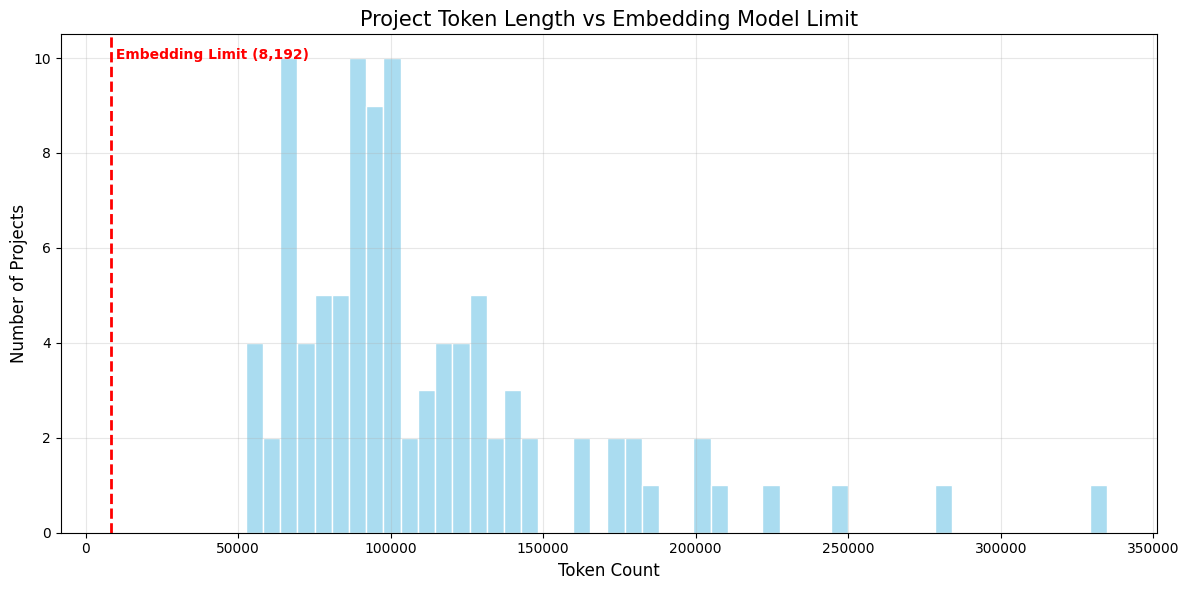


가장 토큰이 많은(긴) 프로젝트 TOP 5


,project_id,title,token_count
32,proj_033,모바일오피스 시스템 고도화 용역(총체 및 1차),334756
15,proj_016,예약발매시스템 개량 ISMP 용역,278478
68,proj_069,철도인프라 디지털트윈 정보화전략계획(ISP) 수립 용역(변경공고),247842
69,proj_070,[재공고][긴급][협상형]운행정보기록 자동분석시스템 개량,222259
7,proj_008,차세대 포털·학사 정보시스템 구축사업,208884


In [ ]:
if not os.path.exists(stats_csv_path):
    print(f"파일이 없음: {stats_csv_path}")
else:
    df = pd.read_csv(stats_csv_path)
    print(f"데이터 로드 완료: {len(df)}개 프로젝트")

    # 토큰 계산기 (GPT-4/5 계열은 'cl100k_base' 인코딩 사용)
    print("정확한 토큰 수 계산 중")
    tokenizer = tiktoken.get_encoding("cl100k_base")
    
    # 텍스트가 비어있을 경우 대비
    df['full_text'] = df['full_text'].fillna("")
    df['token_count'] = df['full_text'].apply(lambda x: len(tokenizer.encode(str(x))))

    # ==========================================
    # [2] 기초 통계 (토큰 기준)
    # ==========================================
    desc_stats = df['token_count'].describe().round(1)
    quantiles = df['token_count'].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

    print("\n" + "="*60)
    print("[GPT 토큰(Token) 기준 기초 통계]")
    print("="*60)
    print(desc_stats)
    print("\n[상위 분포 확인]")
    print(quantiles)

    # ==========================================
    # [3] 임베딩 모델 수용 가능성 분석
    # ==========================================
    print("\n" + "="*60)
    print("[임베딩 모델(Embedding Model) 수용 가능성 분석]")
    print("="*60)
    
    over_count = (df['token_count'] > EMBEDDING_LIMIT).sum()
    pass_count = len(df) - over_count
    pass_ratio = (pass_count / len(df)) * 100
    
    print(f"🔹 Embedding Limit ({EMBEDDING_LIMIT:,}): {pass_count:>3}개 통과 ({pass_ratio:>5.1f}%) | {over_count:>2}개 초과")
    
    if over_count > 0:
        print(f"   - {over_count}개 문서는 임베딩 한도를 초과하므로 '청킹(Chunking)'이 필수입니다.")
        print(f"   - 청킹 없이 넣으면 뒷부분 {df['token_count'].max() - EMBEDDING_LIMIT:,} 토큰 가량이 잘려서 검색되지 않습니다.")
    else:
        print(f"   - 모든 문서가 임베딩 한도 이내입니다.")
    print("-" * 60)

    # ==========================================
    # [4] 시각화 (직관적 비교)
    # ==========================================
    plt.figure(figsize=(12, 6))
    
    # 히스토그램 그리기
    sns.histplot(df['token_count'], bins=50, color='skyblue', edgecolor='white', alpha=0.7)
    
    # 임베딩 한계선 긋기
    plt.axvline(EMBEDDING_LIMIT, color='red', linestyle='--', linewidth=2)
    
    # 텍스트 위치 잡기
    y_max = plt.ylim()[1]
    plt.text(EMBEDDING_LIMIT, y_max * 0.95, f" Embedding Limit ({EMBEDDING_LIMIT:,})", color='red', fontweight='bold', ha='left')

    plt.title('Project Token Length vs Embedding Model Limit', fontsize=15)
    plt.xlabel('Token Count', fontsize=12)
    plt.ylabel('Number of Projects', fontsize=12)
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

    # ==========================================
    # [5] 가장 긴 문서 TOP 5 확인
    # ==========================================
    print("\n가장 토큰이 많은(긴) 프로젝트 TOP 5")
    cols = ['project_id', 'title', 'token_count']
    # display() 함수는 주피터 노트북 전용이므로 print로 대체
df[cols].sort_values(by='token_count', ascending=False).head(5)


# 그래프는 아예 새로 만들어서 세로 점선을 8192(text embedding) 모델로 변경했습니다


## 프로젝트 문서 토큰 분포 분석 및 RAG 전략 도출
            
### 1. 그래프 개요
본 그래프는 프로젝트별 전체 문서(`full_text`)를 토큰(Tiktoken)으로 변환한 뒤,  
텍스트 임베딩 모델의 최대 입력 한계(8,192 tokens)와 비교한 분포를 시각화한 것이다.
- 텍스트 임베딩 모델: text-embedding-3

- X축: 프로젝트별 전체 문서 토큰 수
- Y축: 해당 토큰 구간에 속하는 프로젝트 수
- 빨간 점선: **Embedding Model Input Limit (8,192 tokens)**

---

### 2. 분포 특성 분석

#### 2.1 Embedding max input 크기보다 극단적으로 오른쪽으로 치우친 분포

- 모든 프로젝트 문서가 **최소 수만 토큰 ~ 최대 30만 토큰 이상**으로 구성됨
- 토큰 분포가 임베딩 모델 한계(8k)보다 **압도적으로 오른쪽**에 몰려 있음
- 이는 문서가 “길다” 수준이 아니라 **임베딩 모델 관점에서는 비정상적으로 큼**
- **높은 표준편차(48k):** 표준편차가 매우 크다 즉 문서마다 크기가 제각각이라 **일괄적인 처리 방식으로는 대응이 불가능**
- **평균의 함정:** 평균(111k)이 중앙값(98k)보다 **1.3만 토큰**이나 높다 이는 소수의 거대 프로젝트가 전체 평균을 왜곡하고 있음을 뜻한다

#### 2.2 Embedding 모델 기준 전수 초과
- **모든 프로젝트 문서가 8,192 토큰을 초과**
- 즉, **단 하나의 문서도 통째로 임베딩 불가능**
- 문서 크기 분포와 상관없이:
  
  > 📌 “청킹 없이 임베딩한다”는 선택지는 구조적으로 불가능

---

- 문서를 통째로 임베딩할 수 없음
- 강제로 줄이면:
  - 정보 손실 발생
  - 검색 정확도 붕괴
- 따라서:
  
  > 📌 “검색 가능한 최소 단위”로 문서를 쪼개는 구조가 필수

### 헤더 분포 분석

데이터 로드 중
98개 문서 해부 시작

[분석 진단 결과]
1. 세부 목차(H2/H3) 실종: 98개 문서 (100.0%)
2. 거대 섹션(2000자 초과) 보유: 98개 문서 (100.0%)
3. 가장 긴 섹션(Worst Case): 52,599자 (약 26,300 토큰)


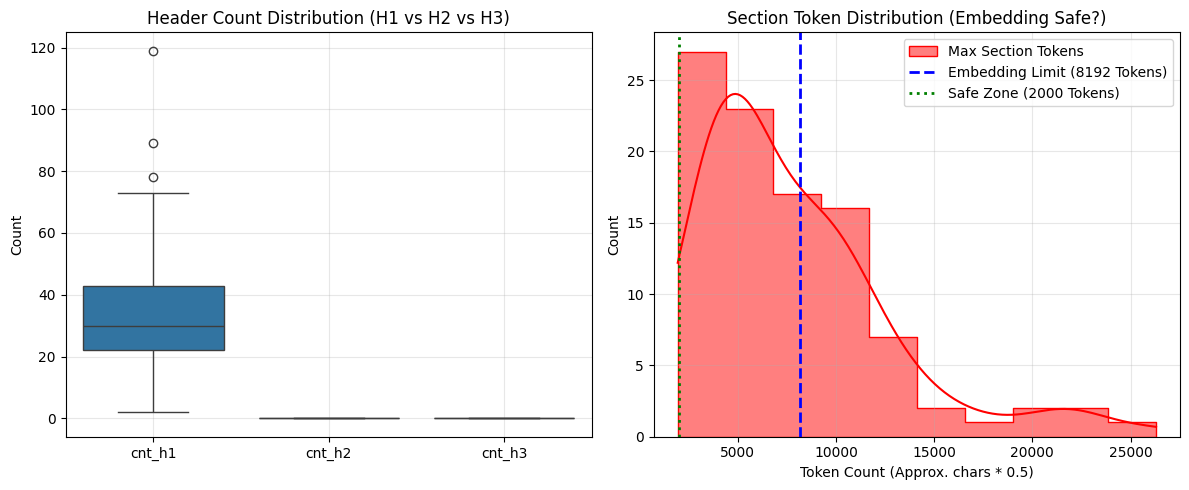

In [7]:
if not os.path.exists(docs_path):
    print("파일이 없음")
    exit()

print("데이터 로드 중")
df = pd.read_csv(docs_path)

# ==========================================
# [분석 함수] 뼈대 해부
# ==========================================
def analyze_skeleton(row):
    text = str(row['full_text'])
    
    # 1. 계층별 헤더 개수 카운트
    h1 = text.count("\n# ")
    h2 = text.count("\n## ")
    h3 = text.count("\n### ")
    total_headers = h1 + h2 + h3
    
    sections = re.split(r'\n\s*#{1,3} ', text)
    
    # 공백 제거 후 길이 측정
    section_lens = [len(s.strip()) for s in sections if len(s.strip()) > 0]
    
    if not section_lens:
        max_sec = 0
        mean_sec = 0
        median_sec = 0
    else:
        max_sec = max(section_lens)      # 가장 긴 챕터의 길이 (글자 수)
        mean_sec = np.mean(section_lens)
        median_sec = np.median(section_lens)
        
    return pd.Series([h1, h2, h3, total_headers, max_sec, mean_sec, median_sec])

# ==========================================
# [실행]
# ==========================================
print(f"{len(df)}개 문서 해부 시작")
cols = ['cnt_h1', 'cnt_h2', 'cnt_h3', 'total_headers', 'max_sec_len', 'mean_sec_len', 'median_sec_len']
df[cols] = df.apply(analyze_skeleton, axis=1)

# ==========================================
# [진단 결과 리포트]
# ==========================================
print("\n" + "="*60)
print("[분석 진단 결과]")
print("="*60)

# 1. 헤더 실종 문서
no_subheaders = len(df[df['cnt_h2'] + df['cnt_h3'] == 0])
print(f"1. 세부 목차(H2/H3) 실종: {no_subheaders}개 문서 ({no_subheaders/len(df)*100:.1f}%)")

# 2. 거대 섹션 존재 여부 (토큰 기준 변환: 글자수 * 0.5)
# 2000자 ≈ 1000토큰
huge_sections = len(df[df['max_sec_len'] > 2000])
print(f"2. 거대 섹션(2000자 초과) 보유: {huge_sections}개 문서 ({huge_sections/len(df)*100:.1f}%)")

# 3. 최악의 경우
worst_max_len = df['max_sec_len'].max()
print(f"3. 가장 긴 섹션(Worst Case): {worst_max_len:,.0f}자 (약 {worst_max_len*0.5:,.0f} 토큰)")

# ==========================================
# [시각화] - X축을 토큰 수로 변경
# ==========================================
plt.figure(figsize=(12, 5))

# 그래프 1: 헤더 개수 분포
plt.subplot(1, 2, 1)
sns.boxplot(data=df[['cnt_h1', 'cnt_h2', 'cnt_h3']])
plt.title("Header Count Distribution (H1 vs H2 vs H3)")
plt.ylabel("Count")
plt.grid(True, alpha=0.3)

# 그래프 2: 섹션 길이 분포 (Token 기준)
plt.subplot(1, 2, 2)

# 글자 수 -> 토큰 수 변환 (약식: 글자수 * 0.5)
# 한글/영어 혼용 문서에서 통상적으로 1글자 ≈ 0.5~0.7 토큰 (GPT-4 기준)
df['max_sec_token'] = df['max_sec_len'] * 0.5 

sns.histplot(df['max_sec_token'], color='red', label='Max Section Tokens', kde=True, element="step")

# 임베딩 한계선 (8192 토큰)
plt.axvline(8192, color='blue', linestyle='--', linewidth=2, label='Embedding Limit (8192 Tokens)')

# 안전 구간 (2000 토큰)
plt.axvline(2000, color='green', linestyle=':', linewidth=2, label='Safe Zone (2000 Tokens)')

plt.title("Section Token Distribution (Embedding Safe?)")
plt.xlabel("Token Count (Approx. chars * 0.5)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# sections = re.split(r'\n\s*#{1,3} ', text) 정규식 수정 (띄어쓰기도 포함)
# 3. 가장 긴 섹션(Worst Case): 52,599자 (약 26,300 토큰)
# 우측 그래프 x축을 글자수에서 토큰으로 변경


- 분석
    - 분석(토큰 분포)이 **"문서가 너무 커서 시스템이 터질 수 있다"**는 거시적인 경고였다면 이번 분석 결과는 **"문서 내부의 뼈대(목차)가 없어서 검색이 길을 잃을 수 있다"**는 구체적인 **구조적 결함**을 보여준다
    - 앞서 확정한 **'이원화 전략(CSV)'**을 실행할 때 **청킹(Chunking) 로직을 어떻게 짜야 하는지** 결정타를 날리는 데이터인 것 같다
    
    - [구조적 해부 분석]
        1. 구조 진단: "허리가 없다 (Flat Structure)"
            * **데이터:** 98개 문서 전체(100%)에서 **H2(중목차), H3(소목차)가 실종**되었다
            * **해석:** 문서가 계층적(트리 구조)으로 정리된 게 아니라 **"1. 대제목(H1)" 하나 아래에 수만 자의 텍스트가 그냥 나열**되어 있다는 뜻이겠다
            * **위험요소:**
                * 일반적인 RAG는 `H1 > H2 > H3`의 맥락을 따라가며 정교하게 검색한다
                * 현재 상태로는 **"이 내용이 예를 들면 '서버 스펙'인지 '네트워크 스펙'인지"** 구분해 줄 중간 표지판(H2/H3)이 없다 오직 H1(대제목) 하나에만 의존해야 한다
            
        2. 청킹 난이도: "소화 불가능한 덩어리 (Indigestible Chunks)"
            * **데이터:**
                * **안전 구간(2,000자) 돌파 100%:** 모든 문서가 임베딩 모델이 한 번에 읽기 벅찬 거대 섹션을 포함하고 있다
                * **최악의 경우(Worst Case):** 단일 챕터가 **52,600자(25,000 토큰)**이다


        * **현실적인 문제:**
            * 우리가 쓸 대부분의 임베딩 모델(OpenAI text-embedding-3 등)은 한 번에 **8,191 토큰**까지만 이해한다
            * 25,000 토큰짜리 챕터를 그대로 넣으면 **뒷부분 16,000 토큰(약 65%)은 짤려서 버려진다** 검색 자체가 안 되는 부분이 압도적으로 많아진다

---

- 조치방법

    **CSV 생성 과정**에서 **"검색용 텍스트(Search Text)"** 컬럼을 만들 때 반드시 적용해야 할 **2단계 분할 전략**이다
        
        Step 1. 마크다운 분할 (뼈대 잡기)
            * **도구:** `MarkdownHeaderSplitter`
            * **기준:** `# (H1)`만 잡는다 (H2, H3는 어차피 없다)
            * **목적:** 최소한의 주제 구분 "이 덩어리는 '1. 사업개요'에 속한다"는 **메타데이터(H1 Title)**를 확보하기 위함이다

        Step 2. 강제 분할 (살 발라내기) - **필수**
            * **도구:** `RecursiveCharacterTextSplitter` (재귀적 분할)
            * **이유:** Step 1만 하면 6만 토큰짜리 덩어리 같은 것들이 그대로 남는다 이걸 기계적으로 또 잘라야 한다
            * **동작:** 12만 자짜리 괴물 챕터를 약 **100개의 작은 조각**으로 난도질할 수 있겠다(정확한 청크 오버랩 사이즈는 뒤에가서 또 다른 결과들을 EDA 한 후 확정을 한다)

        Step 3. 메타데이터 주입 (네임택 붙이기)
            * **문제:** 난도질된 55번째 조각은 무슨 내용인지 모른다
            * **해결:** Step 1에서 잡은 **H1 제목**을 모든 조각의 `search_text` 맨 앞에 강제로 붙여준다
            * *예: " [1. 사업개요] 본 사업은..."*
            * 개념은 거창해 보이지만 구현은 '문자열 더하기' 그 이상도 이하도 아니다 파이썬 코드 안에서 할 일은
                
    - 1차로 자른다: # 1. 사업개요 덩어리를 가져온다
    - 2차로 자른다: 예를 들어 1,000자씩 잘게 쪼갠다 (이때 각 조각은 부모 제목이 '1. 사업개요'라는 걸 알고 있다)
    - 합친다: 조각의 내용 앞에 제목을 풀칠해서 붙여버린다
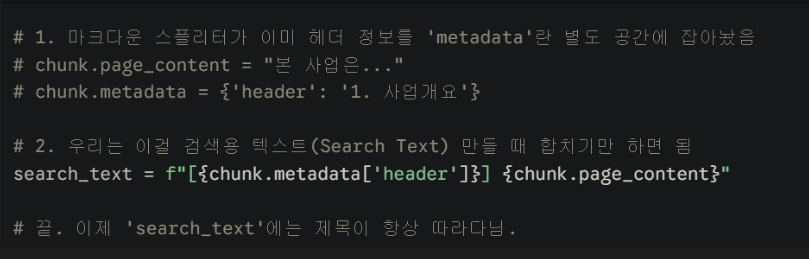
네임택 붙이기는 별도의 어려운 기술이 아니라 두 개의 글자(제목 + 본문)를 이어 붙여서 저장하자는 단순한 규칙이라고 보면 된다

---

- 결론(CSV 작업 지침)

    **문서 구조가 엉망이라(H2/H3 없음) **H1(대제목) 기준으로 1차로 자르고** 그 안의 내용이 너무 기니까 약 **1500자 단위(이건 뒤에가서 얼마로 할지 또 정해볼 예정)로 강제로 2차로 잘라서(Recursive)** CSV 행을 만들어야 한다 안 그러면 뒷내용 다 짤려서 검색 안 된다**

### 표/리스트 및 토큰 효율 분석

In [8]:
# ==========================================
# [진단 결과 리포트]
# ==========================================
print("\n" + "="*60)
print("표/리스트 및 토큰 진단 결과")
print("="*60)

# 1. 토큰 비율 (Chunk Size 결정의 핵심)
avg_ratio = df['token_ratio'].mean()
max_ratio = df['token_ratio'].max()
print(f"1. 토큰 효율(Token/Char Ratio):")
print(f"   - 평균: {avg_ratio:.2f} (한글 1000자 ≈ {1000*avg_ratio:.0f} 토큰)")
print(f"   - 최대: {max_ratio:.2f}")
print(f"     진단: 1200자(Size) 설정 시 약 {1200*avg_ratio:.0f}~{1200*max_ratio:.0f} 토큰 예상.")
print(f"      (임베딩 한도 8191 대비 안전함 1500자까지 늘려도 됨)")

# 2. 표(Table) 리스크 (Overlap 결정의 핵심)
# 표 덩어리가 1000자를 넘어가면 표 중간이 잘릴 위험이 있음
dangerous_tables = len(df[df['max_table_char_len'] > 1000])
avg_table_len = df['max_table_char_len'].mean()  # 평균 표 길이 계산
print(f"\n2. 거대 표(Giant Table) 위험군:")
print(f"   - 1000자(Chunk Size)보다 큰 표를 가진 문서: {dangerous_tables}개")
print(f"   - 가장 거대한 표의 길이: {df['max_table_char_len'].max():,.0f}자")
print(f"   - 표 길이 평균: {avg_table_len:,.0f}자")  # 평균 표 길이 출력

if dangerous_tables > 0:
    print("   - Chunk Size보다 큰 표가 있음 Overlap을 30% 이상(400자+) 줘야 안전")
else:
    print("   - 표들이 작아서 잘릴 위험이 적음")

# 3. 리스트 의존도 (예: 항목1, 항목2 같은 마크다운 리스트나 개조식 문장 수)
high_list_docs = len(df[df['cnt_list_items'] > 50])
print(f"\n3. 리스트(개조식) 과다 문서: {high_list_docs}개")

# ==========================================
# [시각화]
# ==========================================
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['token_ratio'], kde=True, color='green')
plt.title("Token Ratio Distribution (Safe zone?)")
plt.xlabel("Tokens per Character")

plt.subplot(1, 2, 2)
# 표 길이 분포 (로그 스케일 권장)
sns.histplot(df['max_table_char_len'], color='orange')
plt.axvline(1000, color='red', linestyle='--', label='Chunk Size Limit (1000 chars)')
plt.axvline(avg_table_len, color='blue', linestyle=':', label=f'평균 표 길이 ({avg_table_len:,.0f}자)')  # 평균선 추가
plt.title("Max Table Length (Will tables be cut?)")
plt.xlabel("Character Length of Table Block")
plt.legend()

plt.tight_layout()
plt.show()


표/리스트 및 토큰 진단 결과


KeyError: 'token_ratio'

데이터 해부 시작 (총 문서 98개)
텍스트 정밀 스캔 중


100%|██████████| 98/98 [00:01<00:00, 79.48it/s] 



[RFP 데이터 상세 통계 로그]

1. 반복 노이즈 문장 Top 10
--------------------------------------------------
1. [노이즈: 표 템플릿] 커버리지 100.0% | 평균 69.71회/문서: | --- | --- | --- |...
2. [노이즈: 표 템플릿] 커버리지 100.0% | 평균 21.44회/문서: | --- | --- |...
3. [노이즈: 표 템플릿] 커버리지 100.0% | 평균 10.81회/문서: | --- | --- | --- | --- |...
4. [노이즈: 표 템플릿] 커버리지 98.0% | 평균 10.64회/문서: | --- | --- | --- | --- | --- |...
5. [주의] 커버리지 35.7% | 평균 7.93회/문서: | 산출정보 | 산출정보 |  |...
6. [주의] 커버리지 53.1% | 평균 7.53회/문서: | 요구사항 분류 | 요구사항 분류 | 기능 요구사항 |...
7. [주의] 커버리지 20.4% | 평균 7.38회/문서: | 관련요구사항 | 관련요구사항 |  |...
8. [노이즈: 표 템플릿] 커버리지 96.9% | 평균 7.16회/문서: | --- | --- | --- | --- | --- | --- |...
9. [주의] 커버리지 19.4% | 평균 5.20회/문서: | 관련 요구사항 | 관련 요구사항 |  |...
10. [노이즈: 표 템플릿] 커버리지 91.8% | 평균 4.56회/문서: | --- | --- | --- | --- | --- | --- | --- |...

2. 정보 패턴 발견 현황 (총 98개 문서 합계)
--------------------------------------------------
   - 금액(Price): 총 1,006 건 (문서당 평균 10.3 건)
   - 날짜(Date): 총 3,631 건 (문서당 평균 37.1 건)
   - 법률(Law): 총 3,373 건 (문서당 평균 34.4 건)
   - 

/var/folders/53/bz6j7ttj061dc4fqzd1ygd_m0000gn/T/ipykernel_90856/588983889.py:142: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax3.boxplot(data_to_plot, labels=doc_pattern_counts.keys())
/var/folders/53/bz6j7ttj061dc4fqzd1ygd_m0000gn/T/ipykernel_90856/588983889.py:154: UserWarning: Glyph 48152 (\N{HANGUL SYLLABLE BAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/53/bz6j7ttj061dc4fqzd1ygd_m0000gn/T/ipykernel_90856/588983889.py:154: UserWarning: Glyph 48373 (\N{HANGUL SYLLABLE BOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/53/bz6j7ttj061dc4fqzd1ygd_m0000gn/T/ipykernel_90856/588983889.py:154: UserWarning: Glyph 54943 (\N{HANGUL SYLLABLE HOES}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/53/bz6j7ttj061dc4fqzd1ygd_m0000gn/T/ipykernel_90856/588983889.py:154: UserWarning: Glyph 49688 (\N{HANGUL

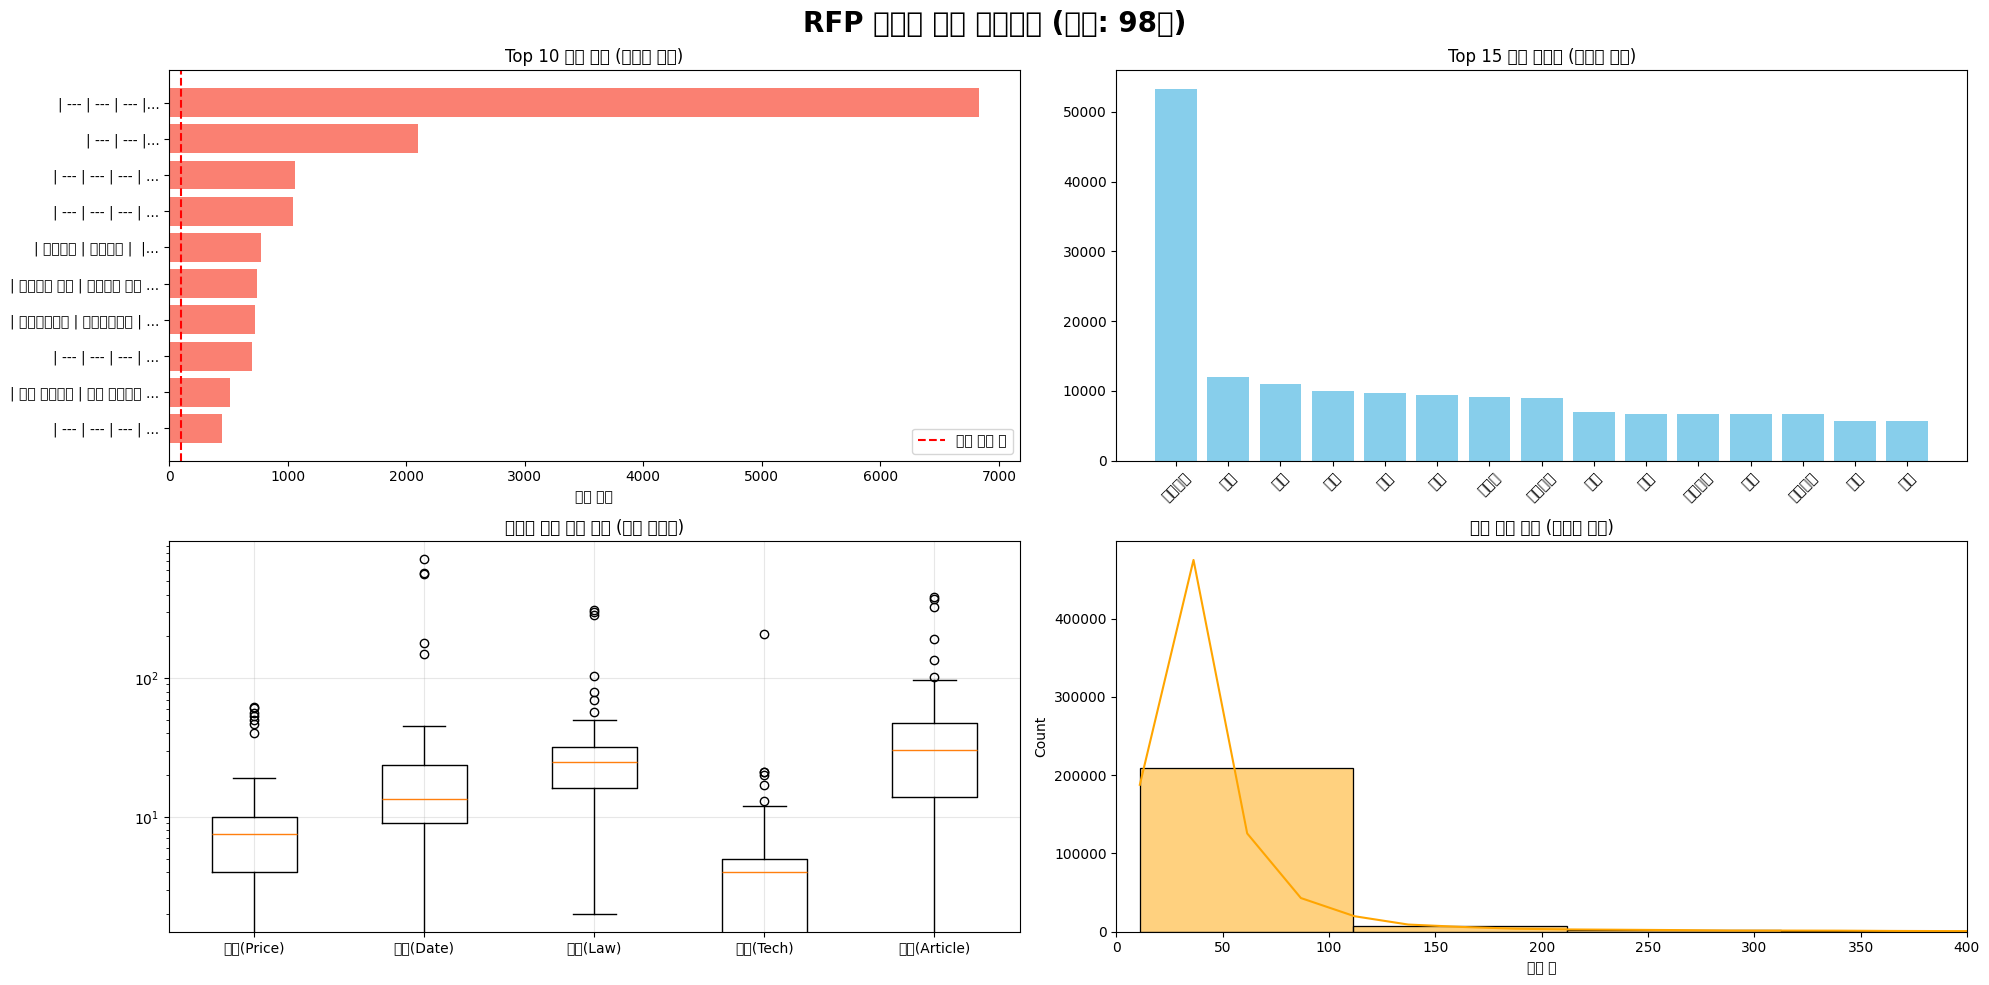

분석 완료


In [6]:
if not os.path.exists(docs_path):
    print("[에러] 파일 없음")
    exit()

df = pd.read_csv(docs_path)
print(f"데이터 해부 시작 (총 문서 {len(df)}개)")
print("="*60)

# ==========================================
# [분석] 패턴 정의 및 스캔
# ==========================================
patterns = {
    '금액(Price)': r'\d{1,3}(?:,\d{3})*\s*(?:만원|억원|원|USD)',
    '날짜(Date)': r'\d{4}[년.-]\s*\d{1,2}[월.-]\s*\d{1,2}일?',
    '법률(Law)': r'(?:법|령|규칙)\s*제\s*\d+\s*조',
    '기술(Tech)': r'[A-Za-z0-9]+(?:Server|DB|API|Cloud|Web|App|Linux|Windows)',
    '조항(Article)': r'제\s*\d+\s*조\s*[\(\[]'
}

all_sentences = []
all_words = []
pattern_counts = {k: 0 for k in patterns.keys()}
doc_pattern_counts = {k: [] for k in patterns.keys()} # 문서별 분포 확인용
sentence_lens = []

print("텍스트 정밀 스캔 중")

for text in tqdm(df['full_text']):
    text = str(text)
    
    # 1. 문장 분석
    sents = [s.strip() for s in re.split(r'\n|\.', text) if len(s.strip()) > 10]
    all_sentences.extend(sents)
    sentence_lens.extend([len(s) for s in sents])
    
    # 2. 단어 분석
    words = re.findall(r'[가-힣]{2,}', text)
    all_words.extend(words)
    
    # 3. 패턴 분석
    for p_name, p_regex in patterns.items():
        found = len(re.findall(p_regex, text, re.IGNORECASE))
        pattern_counts[p_name] += found
        doc_pattern_counts[p_name].append(found)

# ==========================================
# [로그 출력] 상세 통계 리포트
# ==========================================
print("\n" + "="*60)
print("[RFP 데이터 상세 통계 로그]")
print("="*60)

# # 1. 반복 문장 (노이즈)
# print(f"\n1. 반복 노이즈 문장 Top 10 (문서당 평균 반복 횟수 기준)")
# print("-" * 50)

# top_sents = Counter(all_sentences).most_common(10)
# for i, (sent, total_count) in enumerate(top_sents, 1):
#     # 문서당 평균 반복 횟수 계산
#     avg_per_doc = total_count / len(df)
#     # 평균 반복 횟수가 매우 높은 문장을 노이즈로 판단
#     tag = "[노이즈: 표 템플릿]" if avg_per_doc > 10 else "[주의]"
#     print(f"{i}. {tag} 문서당 평균 {avg_per_doc:.1f}회): {sent[:50]}...")

# 1. 반복 문장 (노이즈)
print(f"\n1. 반복 노이즈 문장 Top 10")
print("-" * 50)

# 문장별 총 등장 횟수와 문서 커버리지 계산
sentence_total_counts = Counter(all_sentences)
sentence_docs = defaultdict(set)

for doc_idx, text in enumerate(df['full_text']):
    sents = [s.strip() for s in re.split(r'\n|\.', str(text)) if len(s.strip()) > 10]
    for s in set(sents):  # 중복 제거 후 문서별 등장 여부 기록
        sentence_docs[s].add(doc_idx)

top_sents = sentence_total_counts.most_common(10)

for i, (sent, total_count) in enumerate(top_sents, 1):
    doc_coverage = len(sentence_docs[sent])  # 등장 문서 수
    coverage_pct = (doc_coverage / len(df)) * 100
    avg_per_doc = total_count / len(df)      # 회/문서
    tag = "[노이즈: 표 템플릿]" if coverage_pct > 70 and avg_per_doc > 1.0 else "[주의]"
    print(f"{i}. {tag} 커버리지 {coverage_pct:.1f}% | 평균 {avg_per_doc:.2f}회/문서: {sent[:50]}...")

# 2. 정보 밀도
print(f"\n2. 정보 패턴 발견 현황 (총 {len(df)}개 문서 합계)")
print("-" * 50)
for p_name, count in pattern_counts.items():
    avg = count / len(df)
    print(f"   - {p_name}: 총 {count:,} 건 (문서당 평균 {avg:.1f} 건)")

# 3. 어휘 분포
print(f"\n3. 핵심 키워드 Top 15 (불용어 제외)")
print("-" * 50)
stopwords = ['사업', '구축', '제안', '시스템', '관련', '대한', '따라', '있는', '경우', '위하', '및', '등', '요구', '사항', '관리', '내용', '자료', '제출']
filtered_words = [w for w in all_words if w not in stopwords]
top_words = Counter(filtered_words).most_common(15)
for i, (word, count) in enumerate(top_words, 1):
    print(f"   {i}. {word} ({count:,}회)")

# 4. 문장 호흡
print(f"\n4. 문장 길이 통계")
print("-" * 50)
print(f"   - 평균 길이: {np.mean(sentence_lens):.1f} 자")
print(f"   - 최대 길이: {np.max(sentence_lens):,} 자")
print(f"   - 중간값: {np.median(sentence_lens):.1f} 자")

# ==========================================
# [시각화]
# ==========================================
print("\n그래프 생성 중")

fig = plt.figure(figsize=(20, 10))
plt.suptitle(f"RFP 데이터 해부 대시보드 (문서: {len(df)}개)", fontsize=20, weight='bold')

# 그래프 1: 반복 문장
ax1 = fig.add_subplot(2, 2, 1)
y_pos = np.arange(len(top_sents))
s_counts = [x[1] for x in top_sents]
s_labels = [x[0][:20] + "..." for x in top_sents]
ax1.barh(y_pos, s_counts, align='center', color='salmon')
ax1.set_yticks(y_pos)
ax1.set_yticklabels(s_labels)
ax1.invert_yaxis()
ax1.set_title('Top 10 반복 문장 (노이즈 후보)')
ax1.set_xlabel('반복 횟수')
ax1.axvline(x=len(df), color='red', linestyle='--', label='전체 문서 수')
ax1.legend()

# 그래프 2: 키워드
ax2 = fig.add_subplot(2, 2, 2)
w_labels, w_values = zip(*top_words)
ax2.bar(w_labels, w_values, color='skyblue')
ax2.tick_params(axis='x', rotation=45)
ax2.set_title('Top 15 핵심 키워드 (도메인 파악)')

# 그래프 3: 정보 패턴 분포 (박스플롯)
ax3 = fig.add_subplot(2, 2, 3)
data_to_plot = list(doc_pattern_counts.values())
ax3.boxplot(data_to_plot, labels=doc_pattern_counts.keys())
ax3.set_title('문서별 정보 밀도 편차 (로그 스케일)')
ax3.set_yscale('log')
ax3.grid(True, alpha=0.3)

# 그래프 4: 문장 길이 히스토그램
ax4 = fig.add_subplot(2, 2, 4)
sns.histplot(sentence_lens, bins=50, color='orange', kde=True, ax=ax4)
ax4.set_title('문장 길이 분포 (만연체 확인)')
ax4.set_xlabel('글자 수')
ax4.set_xlim(0, 400)

plt.tight_layout()
plt.show()

print("분석 완료")

In [9]:
import pandas as pd
import re
import os
from collections import Counter

# 파일 경로 설정
docs_path = "rfp_docs.csv"

if not os.path.exists(docs_path):
    print("[에러] 파일 없음")
    exit()

df = pd.read_csv(docs_path)
print(f"데이터 로드 완료: {len(df)}개 문서")

# 1. 모든 텍스트 수집 및 단어 추출 (2글자 이상 한글)
all_words = []
for text in df['full_text']:
    words = re.findall(r'[가-힣]{2,}', str(text))
    all_words.extend(words)

# 2. 불용어(Stopwords) 정의
stopwords = [
]

# 3. 카운팅 (핵심어 vs 불용어)
filtered_words = [w for w in all_words if w not in stopwords]
stopword_words = [w for w in all_words if w in stopwords]

word_counts = Counter(filtered_words)
stopword_counts = Counter(stopword_words)

# 4. 결과 출력
print("\n" + "="*50)
print("[불용어 제외 핵심 키워드 Top 15]")
print("="*50)
for i, (word, count) in enumerate(word_counts.most_common(15), 1):
    print(f"{i}. {word} ({count:,}회)")

print("\n" + "="*50)
print("[제거된 불용어(Stopwords) 빈도 Top 15]")
print("="*50)
for i, (word, count) in enumerate(stopword_counts.most_common(15), 1):
    print(f"{i}. {word} ({count:,}회)")


데이터 로드 완료: 98개 문서

[불용어 제외 핵심 키워드 Top 15]
1. 요구사항 (53,287회)
2. 경우 (13,053회)
3. 한다 (11,964회)
4. 또는 (10,971회)
5. 대한 (10,673회)
6. 시스템 (10,346회)
7. 분류 (9,960회)
8. 명칭 (9,732회)
9. 기능 (9,489회)
10. 관리 (9,418회)
11. 데이터 (9,110회)
12. 고유번호 (9,004회)
13. 관련 (7,825회)
14. 따라 (7,725회)
15. 사업 (7,286회)

[제거된 불용어(Stopwords) 빈도 Top 15]
